# Statistics 1: Describing data

*Learning path: probability and statistics, part 1 of 8.* [Index](README.md) · Previous: [Simplify and eval](00-simplify-and-eval.ipynb) · Next: [Probability and simulation](02-probability-and-simulation.ipynb)

A newspaper says the average household income in a city is 64,000, but most households earn less than that. A class
reports the mean exam score, and one student wants to know whether 71 is good. A doctor reads that a child's height is
"at the 90th percentile". Each of these is a question about a **list of numbers**: where its centre is, how spread out
it is, and what shape it has. This lesson is about describing such a list honestly, with a few numbers and one
picture, the histogram.

**Who this is for.** Students starting a first statistics course. You need only arithmetic and square roots; sums of
lists are explained as we go.

**What you will be able to do afterwards:**

1. compute and interpret the mean, median and mode, and say when they disagree;
2. measure spread with the standard deviation and the interquartile range;
3. draw and read a histogram, and describe a distribution as symmetric or skewed;
4. compare values from different lists with z-scores.

Plan about 45 minutes. Each section ends with a **Try this**; exercises, hints and answers are at the end.

## 1. Centre: mean, median and mode

Here are eight measurements: $2, 4, 4, 4, 5, 5, 7, 9$. The **mean** is the sum divided by the count,
$40/8 = 5$. The **median** is the middle value after sorting; with an even count it is the average of the two middle
values, here $(4 + 5)/2 = 9/2$. The **mode** is the most frequent value, 4. Galileo keeps whole numbers and fractions
exact:

In [1]:
x = [2 4 4 4 5 5 7 9];
mean(x)
median(x)
mode(x)
tally(x)

5

> Mean: the sum of the 8 values divided by 8.

9/2

> Median: the middle value after sorting (the average of the two middle values when the count is even). Half the data lie below it, half above; unlike the mean it ignores how extreme the extremes are.

4

> Mode: the most frequent value (3 times).

[2, 4, 5, 7, 9;
 1, 3, 2, 1, 1]

> tally: the first row lists the distinct values, the second how often each occurs.

`tally` lists each value with how often it occurs. The mean is the balance point of the data: the deviations from it,
$x_i - \bar x$, add up to zero.

In [2]:
d = x - mean(x)
sum(d)

[-3, -1, -1, -1, 0, 0, 2, 4]

> Mean: the sum of the 8 values divided by 8.

0

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

**Try this.** Replace the 9 by 90. How do the mean and the median change? Which one would you report for "typical"?

In [3]:
y = [2 4 4 4 5 5 7 90];
[mean(y), median(y)]

[121/8, 9/2]

> Mean: the sum of the 8 values divided by 8.
>
> Median: the middle value after sorting (the average of the two middle values when the count is even). Half the data lie below it, half above; unlike the mean it ignores how extreme the extremes are.

## 2. Spread: standard deviation and quartiles

Two classes can have the same mean score and very different spreads. The **sample variance** averages the squared
deviations, dividing by $n - 1$ (section 5 of [lesson 6](06-estimation-and-confidence.ipynb) explains why), and the
**standard deviation** is its square root, in the same units as the data:

$$s^2 = \frac{1}{n - 1}\sum_{i=1}^n (x_i - \bar x)^2, \qquad s = \sqrt{s^2}.$$

The sum of squares is a dot product of the deviations with themselves, $d\,d^T$:

In [4]:
d*d'
var(x)
std(x)

32

32/7

> Sample variance: the sum of squared deviations from the mean divided by n − 1 = 7 (dividing by n − 1 instead of n makes it an unbiased estimate of the population variance).

4*sqrt(2/7)

> Sample standard deviation: the square root of the sample variance (sum of squared deviations divided by n − 1 = 7).

So $s^2 = 32/7$ and $s = 4\sqrt{2/7} \approx 2.14$. A second measure of spread uses the **quartiles**: the first
quartile $Q_1$ has a quarter of the data below it, the third $Q_3$ three quarters. `summary` gives the **five-number
summary** [minimum, $Q_1$, median, $Q_3$, maximum], and the **interquartile range** $Q_3 - Q_1$ is in its note:

In [5]:
summary(x)

[2, 4, 9/2, 11/2, 9]

> Five-number summary [minimum, first quartile, median, third quartile, maximum] of 8 values. Mean 5, standard deviation 4*sqrt(2/7), interquartile range 3/2.

The interquartile range $11/2 - 4 = 3/2$ covers the middle half of the data. Unlike the standard deviation, it ignores
the extremes completely, just as the median does.

**Try this.** Compute `std(y)` and `summary(y)` for the list with 90 in it. Which measure of spread barely changes?

## 3. Histograms and shape

A short list can be read directly. For hundreds of values we need a picture. A **histogram** cuts the range into
equal bins and draws a bar for the number of values in each. Here are 500 simulated adult heights in centimetres
(`randn` gives random numbers from the bell curve of [lesson 4](04-continuous-distributions.ipynb); `seed` makes the
same numbers come out every time you run the notebook):

[145.9, 164.7, 170.4, 175.9, 190.0]

> `round` (see `floor`): Round down, up, or to the nearest whole number; round(x, d) keeps d decimals.

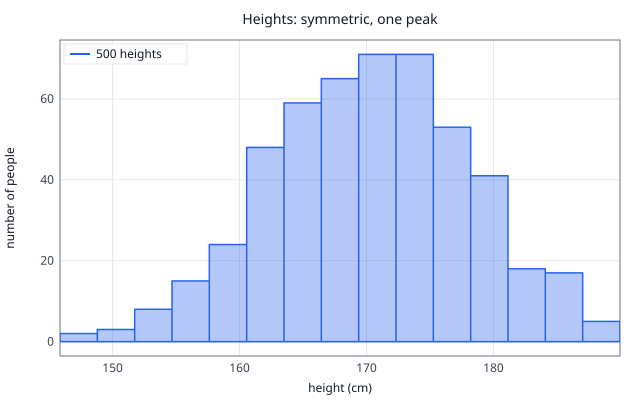

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
seed(2026);
h = 170 + 8*randn(1, 500);
round(summary(h), 1)
p = hist(h, 15);
labels(title(legend(p, "500 heights"), "Heights: symmetric, one peak"), "height (cm)", "number of people")

The histogram is **symmetric** around its single peak, so mean and median are almost equal (170.2 and 170.4). Now
incomes, which are typically **skewed to the right**: most people earn a moderate amount and a few earn a great deal.

[26413.0, 22283.0]

> `round` (see `floor`): Round down, up, or to the nearest whole number; round(x, d) keeps d decimals.

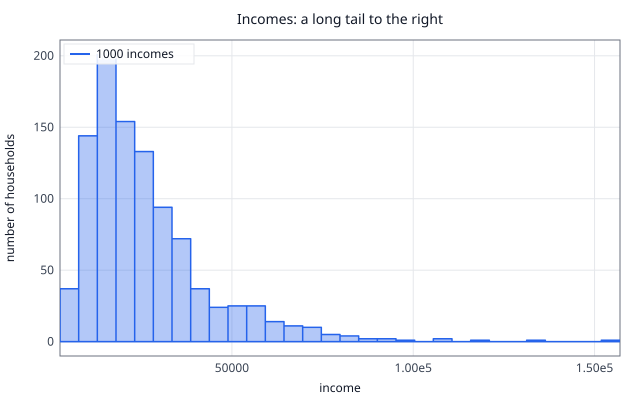

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
inc = exp(10 + 0.6*randn(1, 1000));
round([mean(inc), median(inc)], 0)
p = hist(inc, 30);
labels(title(legend(p, "1000 incomes"), "Incomes: a long tail to the right"), "income", "number of households")

The long right tail pulls the mean (26,400) far above the median (22,300): the newspaper's "average income" is
correct and still gives the wrong idea of a typical household. **For skewed data, report the median.**

The number of bins matters: too few hide the shape, too many turn it into noise. Galileo's default is
$\lceil\log_2 n\rceil + 1$ bins (Sturges' rule), and you can give your own.

**Try this.** Draw `hist(h, 5)` and `hist(h, 60)`. Which shows the shape best?

## 4. z-scores: comparing across lists

Is 71 a good exam score? In a class with mean 65 and standard deviation 4, it is $1.5$ standard deviations above the
mean; in a class with mean 70 and standard deviation 10, it is only $0.1$ above. The **z-score**
$z = (x - \bar x)/s$ measures a value in standard deviations from the mean, so values from different lists can be
compared.

For bell-shaped data, about 68% of values have $|z| < 1$ and about 95% have $|z| < 2$. Check it with the heights:
`abs(z) < 1` is 1 where the condition holds and 0 where it does not, so its sum counts.

In [8]:
z = (h - mean(h))/std(h);
sum(abs(z) < 1)/500
sum(abs(z) < 2)/500

337/500

477/500

67.4% and 95.4%: close to the rule. [Lesson 4](04-continuous-distributions.ipynb) explains where 68% and 95% come
from.

**Try this.** A child is 132 cm tall in a group with mean 125 cm and standard deviation 5 cm. What is the z-score?
Roughly what fraction of the group is taller?

## Summary

* Centre: the mean (balance point, sensitive to extremes) and the median (middle value, robust).
* Spread: the standard deviation $s$ (divide by $n - 1$) and the interquartile range $Q_3 - Q_1$.
* The histogram shows shape: symmetric or skewed, one peak or several. For skewed data, report the median and
  quartiles.
* z-scores measure a value in standard deviations from the mean; for bell-shaped data about 68% lie within 1 and 95%
  within 2.

Next: [probability and simulation](02-probability-and-simulation.ipynb).

## Exercises

1. **By hand.** For $3, 7, 8, 10, 12$ compute the mean, median and standard deviation, then check with Galileo.
2. **Effect of a constant.** If every value is increased by 5, what happens to the mean, median and standard
   deviation? If every value is doubled?
3. **Two classes.** Class A scored `[62 65 68 70 70 71 74 80]`, class B `[45 55 60 70 75 85 90 95]`. Compare their
   centres and spreads, and describe each in one sentence.
4. **Mean versus median.** Make a list of five numbers whose mean is larger than every one of its values but one.
5. **Simulated dice.** Use `randint(1, 6, 600)` and `tally` to roll a die 600 times. Draw a histogram with edges
   `[0.5 1.5 2.5 3.5 4.5 5.5 6.5]`. Does it look flat?

## Hints and answers

* **Section 1, Try this.** The mean jumps from 5 to 15.125; the median stays at 9/2. The median.
* **Section 2, Try this.** `std(y)` jumps to about 30.3; the interquartile range stays 3/2.
* **Section 3, Try this.** 5 bins hide the bell shape; 60 bins are ragged. Around 15 to 20 bins show it best.
* **Section 4, Try this.** $z = 1.4$; for a bell shape about 8% are taller.
* **Exercise 1.** Mean 8, median 8, $s^2 = (25 + 1 + 0 + 4 + 16)/4 = 23/2$, $s = \sqrt{23/2} \approx 3.39$.
* **Exercise 2.** Adding 5 adds 5 to mean and median and leaves $s$ unchanged; doubling doubles all three.
* **Exercise 3.** Means 70 and 71.875, nearly equal; standard deviations about 5.5 and 17.7: class A is consistent,
  class B is spread out.
* **Exercise 4.** For example $1, 1, 1, 1, 100$: mean 20.8.
* **Exercise 5.** Each face appears about 100 times; differences of 10 or 20 are normal chance variation, as lesson 7
  will make precise.

## Sources

1. D. Freedman, R. Pisani and R. Purves, *Statistics*, 4th ed., Norton (2007), chapters 3 to 5.
2. J. W. Tukey, *Exploratory Data Analysis*, Addison-Wesley (1977) (the five-number summary).
3. H. A. Sturges, "The choice of a class interval", *Journal of the American Statistical Association* 21 (1926) 65–66.